# Euler System of Gas Dynamics

In [1]:
import math, numpy
import matplotlib
matplotlib.rc( 'image', cmap='jet' )
from matplotlib import pyplot
from ufl import *
from dune.generator import path
from dune.grid import structuredGrid, reader
from dune.fem.space import dgonb, finiteVolume
from dune.fem.function import gridFunction
from dune.femdg import femDGOperator
from dune.femdg.rk import femdgStepper
from dune.fem.utility import lineSample

Basic model for hyperbolic conservation law

In [2]:
class Model:
    gamma = 1.4
    # helper function
    def toPrim(U):
        v = as_vector( [U[i]/U[0] for i in range(1,3)] )
        kin = dot(v,v) * U[0] / 2
        pressure = (Model.gamma-1)*(U[3]-kin)
        return U[0], v, pressure

    # interface methods for model
    def F_c(t,x,U):
        rho, v, p = Model.toPrim(U)
        return as_matrix( [
                  [rho*v[0], rho*v[1]],
                  [rho*v[0]*v[0] + p, rho*v[0]*v[1]],
                  [rho*v[0]*v[1], rho*v[1]*v[1] + p],
                  [(U[3]+p)*v[0], (U[3]+p)*v[1]] ] )
    # simple 'outflow' boundary conditions on all boundaries
    boundary = {range(1,5): lambda t,x,U: U}

    # interface method needed for LLF and time step control
    def maxLambda(t,x,U,n):
        rho, v, p = Model.toPrim(U)
        return abs(dot(v,n)) + sqrt(Model.gamma*p/rho)

Add methods for limiting

In [3]:
def velocity(t,x,U):
    _, v ,_ = Model.toPrim(U)
    return v
def physical(t,x,U):
    rho, _, p = Model.toPrim(U)
    return conditional( rho>1e-8, conditional( p>1e-8 , 1, 0 ), 0 )
def jump(t,x,U,V):
    _,_, pL = Model.toPrim(U)
    _,_, pR = Model.toPrim(V)
    return (pL - pR)/(0.5*(pL + pR))
Model.velocity = velocity
Model.physical = physical
Model.jump     = jump

Method to evolve the solution in time

In [4]:
def evolve(space, u_h, limiter="MinMod"):
    lu_h = u_h.localFunction()
    @gridFunction(space.grid,name="rho",order=space.order)
    def rho(e,x):
        lu_h.bind(e)
        return lu_h(x)[0]
    operator = femDGOperator(Model,space, limiter=limiter) # note: that u_h.space fails since not ufl_space
    stepper  = femdgStepper(order=space.order if space.order else 2, operator=operator)
    operator.applyLimiter(u_h)
    t = 0
    saveStep = 0.01
    c = 0
    fig = pyplot.figure(figsize=(30,10))
    rho.plot(gridLines="white", figure=(fig, 131+c), colorbar=False, clim=[0.125,1])
    while t < 0.3:
        operator.setTime(t)
        t += stepper(u_h)
        print(t)
        if t > saveStep:
            saveStep += 0.1
            c += 1
            rho.plot(gridLines="white", figure=(fig, 131+c), colorbar=False, clim=[0.125,1])
    # return lineSample(u_h,[0,0],[1,1],200)
    res = numpy.zeros((2,space.grid.size(0)))
    for i,e in enumerate(space.grid.elements):
        x = e.geometry.center
        res[0][i] = x.two_norm
        res[1][i] = rho(e,e.geometry.toLocal(x))
    pyplot.show()
    return res

A radial Rieman problem

*************************************
POLYB


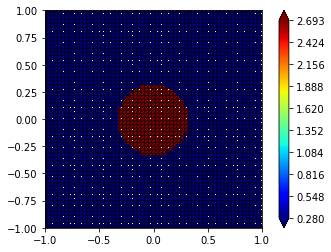

0.004724555912615152
0.0094491118252303


0.014173667737845445


0.018898223650460587


0.02362277956307572
0.028347335475690853
0.03307189138830598
0.0377964473009211


0.04252100321353622
0.04724555912615133
0.051970115038766446


...


0.23622779563075494
0.24095235154337002


0.2456769074559851
0.2504014633686002
0.2551260192812153
0.2598505751938304


0.26457513110644554
0.26929968701906065


0.27402424293167577
0.2787487988442909
0.283473354756906
0.2881979106695211
0.2929224665821362
0.29764702249475133


0.30237157840736645


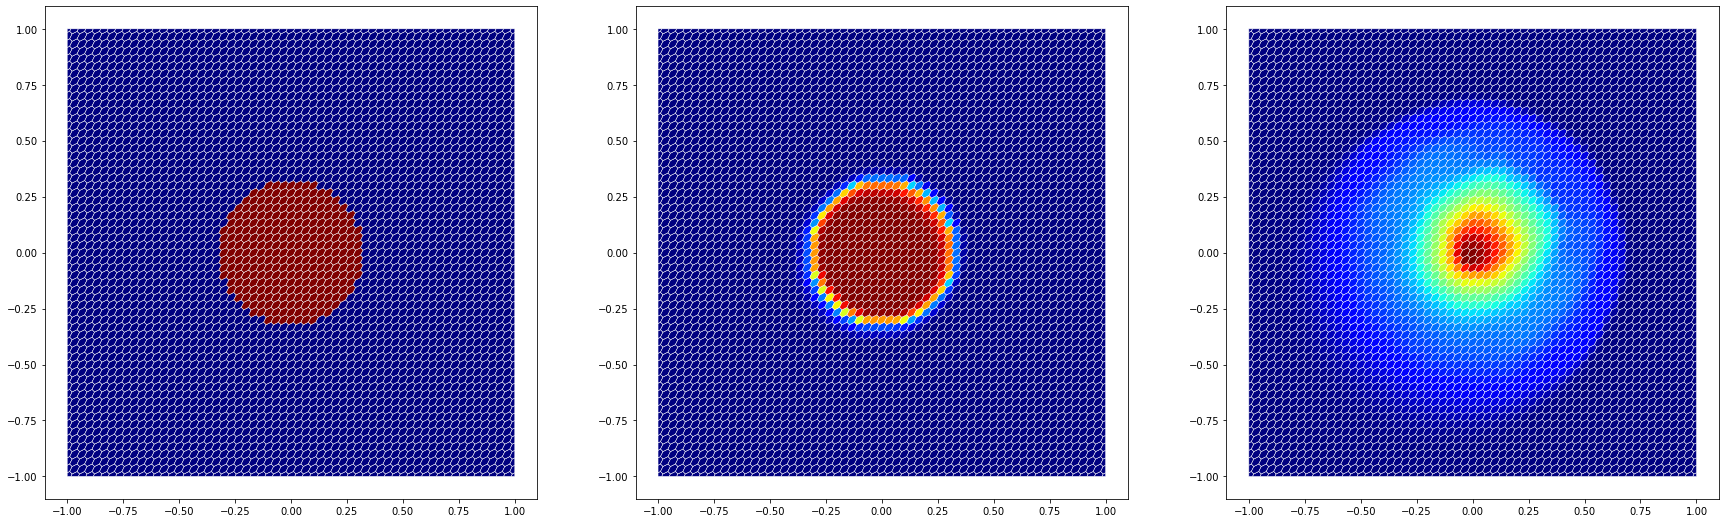

POLYC


0.004724555912615152
0.009449111825230304
0.014173667737845456


0.018898223650460608
0.02362277956307576
0.02834733547569091
0.03307189138830606
0.037796447300921215


0.04252100321353637
0.047245559126151526
0.05197011503876668
0.05669467095138183
0.06141922686399698


0.06614378277661213
0.07086833868922729
0.07559289460184244
0.0803174505144576
0.08504200642707276
0.08976656233968791


...


0.20315590424245142
0.20788046015506656
0.2126050160676817


0.21732957198029684
0.22205412789291198
0.22677868380552713
0.23150323971814227
0.2362277956307574


0.24095235154337255
0.2456769074559877
0.2504014633686028
0.2551260192812179
0.259850575193833
0.2645751311064479


0.26929968701906265
0.27402424293167693
0.2787487988442904
0.2834733547569022
0.288197910669511


0.29292246658211424
0.2976470224947073
0.3023715784072823


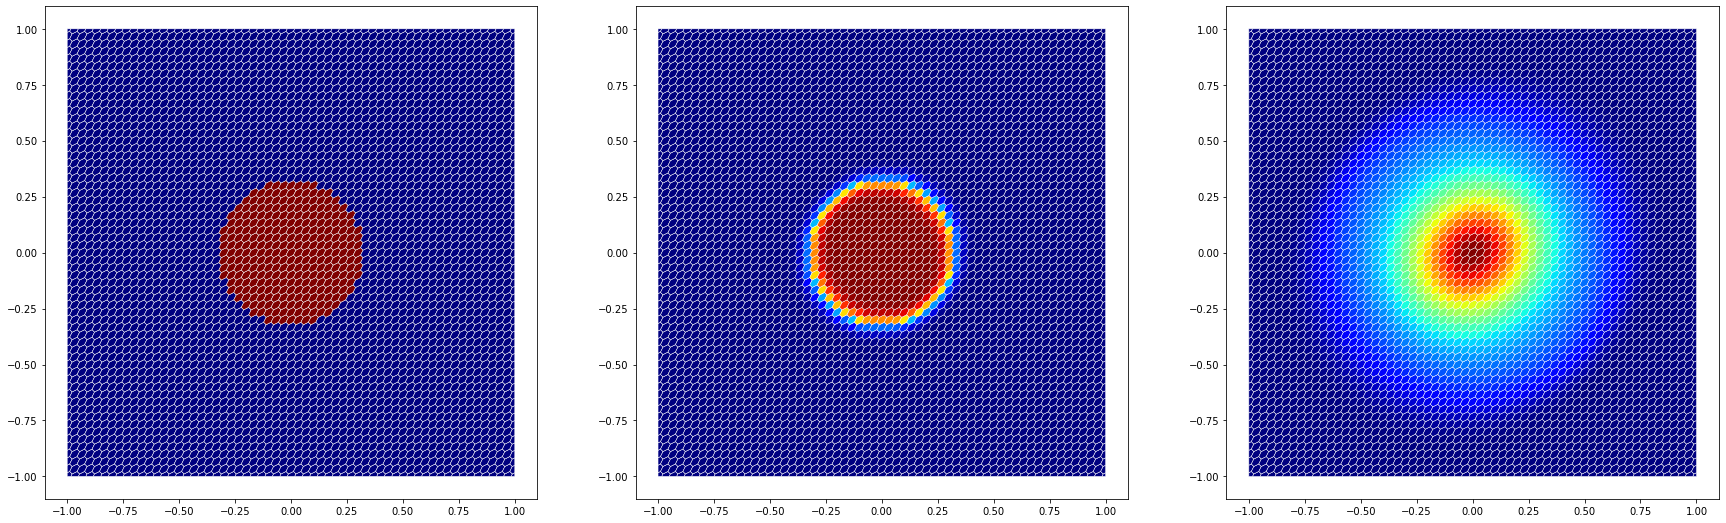

In [5]:
x = SpatialCoordinate(triangle)
initial = conditional(dot(x,x)<0.1,as_vector([1,0,0,2.5]),
                                   as_vector([0.125,0,0,0.25]))

domain = (reader.dgf, "triangle.dgf")
try:
    from dune.polygongrid import polygonGrid
    gridView = polygonGrid( domain, dualGrid=True )
except ImportError:
    print("dune.polygongrid module not found using a simplex grid instead - ignored")
    from dune.alugrid import aluSimplexGrid as simplexGrid
    gridView = simplexGrid( domain, dimgrid=2 )

print("*************************************")

print("POLYB", flush=True)
space = finiteVolume( gridView, dimRange=4 )
u_h   = space.interpolate( initial, name="solution")
u_h.plot()
res   = [evolve(space,u_h)]

print("POLYC", flush=True)
u_h   = space.interpolate( initial, name="solution")
res  += [evolve(space,u_h,limiter=None)]

Solutions along the diagonal

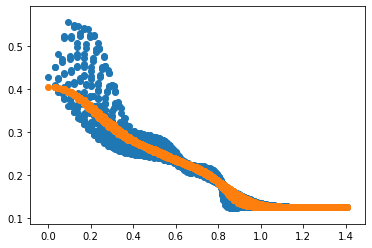

In [6]:
pyplot.scatter(res[0][0],res[0][1])
pyplot.scatter(res[1][0],res[1][1])
# pyplot.scatter(res[2][0],res[2][1])
pyplot.show()